In [1]:
## import basic library

import os
import laspy
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
## list main las folders

las_folder = "../data/pointclouds"

files = os.listdir(las_folder)

files

['20 kmh.las', '30 kmh.las', '40 kmh.las']

In [3]:
def check_attributes(path):

    with laspy.open(path) as f:
        header = f.header
        
        print("Number of points:", header.point_count)
        print("Point format:", header.point_format)
        print("Version:", header.version)
        print("Scale:", header.scales)
        print("Offset:", header.offsets)
        print("CRS:", header.parse_crs())
        print("Minimum coordinates:")
        print(header.mins)
        print("Maximum coordinates:")
        print(header.maxs)
        Attributes = (list(header.point_format.dimension_names))
        for i in Attributes:
            print(i)
    

In [4]:
# check availability of each attribute of 20kmh point cloud

path_20 = "../data/pointclouds/20 kmh.las"
check_attributes(path=path_20)

Number of points: 134129902
Point format: <PointFormat(3, 0 bytes of extra dims)>
Version: 1.2
Scale: [0.001 0.001 0.001]
Offset: [3.71770572e+05 5.64356644e+06 1.54559000e+02]
CRS: EPSG:32632
Minimum coordinates:
[3.71353963e+05 5.64312230e+06 1.44986000e+02]
Maximum coordinates:
[3.71865884e+05 5.64377990e+06 1.96485000e+02]
X
Y
Z
intensity
return_number
number_of_returns
scan_direction_flag
edge_of_flight_line
classification
synthetic
key_point
withheld
scan_angle_rank
user_data
point_source_id
gps_time
red
green
blue


In [5]:
## Check 30kmh pointcloud file and its attributes

path_30 = "../data/pointclouds/30 kmh.las"
check_attributes(path=path_30)


Number of points: 104427485
Point format: <PointFormat(3, 0 bytes of extra dims)>
Version: 1.2
Scale: [0.001 0.001 0.001]
Offset: [3.71775169e+05 5.64355635e+06 1.54146000e+02]
CRS: EPSG:32632
Minimum coordinates:
[3.71354004e+05 5.64312387e+06 1.45307000e+02]
Maximum coordinates:
[3.71881532e+05 5.64377888e+06 1.96483000e+02]
X
Y
Z
intensity
return_number
number_of_returns
scan_direction_flag
edge_of_flight_line
classification
synthetic
key_point
withheld
scan_angle_rank
user_data
point_source_id
gps_time
red
green
blue


In [ ]:
## Check 40kmh pointcloud file and its attributes

path_40 = "../data/pointclouds/40 kmh.las"
check_attributes(path=path_40)

Number of points: 105708638
Point format: <PointFormat(3, 0 bytes of extra dims)>
Version: 1.2
Scale: [0.001 0.001 0.001]
Offset: [3.71774466e+05 5.64355587e+06 1.54134000e+02]
CRS: EPSG:32632
Minimum coordinates:
[3.71533000e+05 5.64145849e+06 1.22735000e+02]
Maximum coordinates:
[3.71970706e+05 5.64374213e+06 1.77532000e+02]
X
Y
Z
intensity
return_number
number_of_returns
scan_direction_flag
edge_of_flight_line
classification
synthetic
key_point
withheld
scan_angle_rank
user_data
point_source_id
gps_time
red
green
blue


In [7]:
# Inspect pipeline GIS files

hal = gpd.read_file("../data/leitungen/HAL.shp")
vl = gpd.read_file("../data/leitungen/VL.shp")

print("HAL")
print(hal.head())

print("VL")
print(vl.head())

HAL
   id                                           geometry
0 NaN  LINESTRING (371468.763 5643371.997, 371467.579...
1 NaN  LINESTRING (371464.088 5643372.552, 371463.887...
2 NaN  LINESTRING (371434.437 5643376.356, 371435.696...
3 NaN  LINESTRING (371433.776 5643376.299, 371429.145...
4 NaN  LINESTRING (371477.31 5643370.982, 371475.524 ...
VL
   id                                           geometry
0 NaN  LINESTRING (371769.669 5643555.217, 371771.001...
1 NaN  LINESTRING (371771.714 5643566.82, 371765.809 ...
2 NaN  LINESTRING (371510.596 5643402.965, 371526.282...
3 NaN  LINESTRING (371515.939 5643423.438, 371530.932...
4 NaN  LINESTRING (371501.931 5643368.179, 371433.776...


In [8]:
# Check coordinate systems

print("HAL CRS:", hal.crs)
print("VL CRS:", vl.crs)


HAL CRS: EPSG:25832
VL CRS: EPSG:25832


In [9]:
# Read points in chunks

def sample_las_points(path, max_points=500000):

    sampled = []

    with laspy.open(path) as f:

        total_points = f.header.point_count

        # calculate approximate sampling ratio
        sample_per_chunk = 5000

        for chunk in f.chunk_iterator(max_points):

            n = len(chunk.x)

            idx = np.random.choice(
                n,
                size=min(sample_per_chunk, n),
                replace=False
            )

            sampled.append(
                np.column_stack(
                    (
                        chunk.x[idx],
                        chunk.y[idx],
                        chunk.z[idx]
                    )
                )
            )

            


    points = np.vstack(sampled)

    return points

In [10]:
points = sample_las_points(path_40)

print("Sample size:", points.shape)

Sample size: (1060000, 3)


In [11]:
def check_field(las_path, field_name, chunk_size=5000000):
    value_counts = {}
    with laspy.open(las_path) as f:
        dims = list(f.header.point_format.dimension_names)
        if field_name not in dims:
            print(f"{field_name}: NOT PRESENT in file format")
            return

        for chunk in f.chunk_iterator(chunk_size):
            vals = np.array(getattr(chunk, field_name))
            for v, c in zip(*np.unique(vals, return_counts=True)):
                value_counts[v] = value_counts.get(v, 0) + c

    n_unique = len(value_counts)
    print(f"{field_name}: {n_unique} unique value(s)")
    if n_unique <= 5:
        print(f"  Values: {value_counts}")
    else:
        vals = np.array(list(value_counts.keys()))
        print(f"  Range: {vals.min()} to {vals.max()}")

In [ ]:
# Number of attributes to check

fields_to_check = [
    "intensity", "return_number", "number_of_returns",
    "scan_direction_flag", "edge_of_flight_line", "classification",
    "synthetic", "key_point", "withheld", "scan_angle_rank",
    "user_data", "point_source_id", "gps_time", "red", "green", "blue"
]


In [13]:
# check availability of each attribute of 20kmh point cloud

for field in fields_to_check:
        check_field(path_20, field)

intensity: 106 unique value(s)
  Range: 0 to 255
return_number: 2 unique value(s)
  Values: {np.uint8(1): np.int64(127196206), np.uint8(2): np.int64(6933696)}
number_of_returns: 1 unique value(s)
  Values: {np.uint8(0): np.int64(134129902)}
scan_direction_flag: 1 unique value(s)
  Values: {np.uint8(0): np.int64(134129902)}
edge_of_flight_line: 1 unique value(s)
  Values: {np.uint8(0): np.int64(134129902)}
classification: 1 unique value(s)
  Values: {np.uint8(0): np.int64(134129902)}
synthetic: 1 unique value(s)
  Values: {np.uint8(0): np.int64(134129902)}
key_point: 1 unique value(s)
  Values: {np.uint8(0): np.int64(134129902)}
withheld: 1 unique value(s)
  Values: {np.uint8(0): np.int64(134129902)}
scan_angle_rank: 1 unique value(s)
  Values: {np.int8(0): np.int64(134129902)}
user_data: 1 unique value(s)
  Values: {np.uint8(0): np.int64(134129902)}
point_source_id: 1 unique value(s)
  Values: {np.uint16(0): np.int64(134129902)}
gps_time: 726 unique value(s)
  Range: 291140.733 to 2918

In [14]:
# check availability of each attribute of 30kmh point cloud

for field in fields_to_check:
        check_field(path_30, field)

intensity: 106 unique value(s)
  Range: 0 to 255
return_number: 2 unique value(s)
  Values: {np.uint8(1): np.int64(99164982), np.uint8(2): np.int64(5262503)}
number_of_returns: 1 unique value(s)
  Values: {np.uint8(0): np.int64(104427485)}
scan_direction_flag: 1 unique value(s)
  Values: {np.uint8(0): np.int64(104427485)}
edge_of_flight_line: 1 unique value(s)
  Values: {np.uint8(0): np.int64(104427485)}
classification: 1 unique value(s)
  Values: {np.uint8(0): np.int64(104427485)}
synthetic: 1 unique value(s)
  Values: {np.uint8(0): np.int64(104427485)}
key_point: 1 unique value(s)
  Values: {np.uint8(0): np.int64(104427485)}
withheld: 1 unique value(s)
  Values: {np.uint8(0): np.int64(104427485)}
scan_angle_rank: 1 unique value(s)
  Values: {np.int8(0): np.int64(104427485)}
user_data: 1 unique value(s)
  Values: {np.uint8(0): np.int64(104427485)}
point_source_id: 1 unique value(s)
  Values: {np.uint16(0): np.int64(104427485)}
gps_time: 584 unique value(s)
  Range: 292237.811 to 29276

In [15]:
# check availability of each attribute of 40kmh point cloud

for field in fields_to_check:
        check_field(path_40, field)

intensity: 106 unique value(s)
  Range: 0 to 255
return_number: 2 unique value(s)
  Values: {np.uint8(1): np.int64(99894376), np.uint8(2): np.int64(5814262)}
number_of_returns: 1 unique value(s)
  Values: {np.uint8(0): np.int64(105708638)}
scan_direction_flag: 1 unique value(s)
  Values: {np.uint8(0): np.int64(105708638)}
edge_of_flight_line: 1 unique value(s)
  Values: {np.uint8(0): np.int64(105708638)}
classification: 1 unique value(s)
  Values: {np.uint8(0): np.int64(105708638)}
synthetic: 1 unique value(s)
  Values: {np.uint8(0): np.int64(105708638)}
key_point: 1 unique value(s)
  Values: {np.uint8(0): np.int64(105708638)}
withheld: 1 unique value(s)
  Values: {np.uint8(0): np.int64(105708638)}
scan_angle_rank: 1 unique value(s)
  Values: {np.int8(0): np.int64(105708638)}
user_data: 1 unique value(s)
  Values: {np.uint8(0): np.int64(105708638)}
point_source_id: 1 unique value(s)
  Values: {np.uint16(0): np.int64(105708638)}
gps_time: 585 unique value(s)
  Range: 292896.828 to 29342


Processing: 30 kmh.las
Sample size: (1045000, 3)


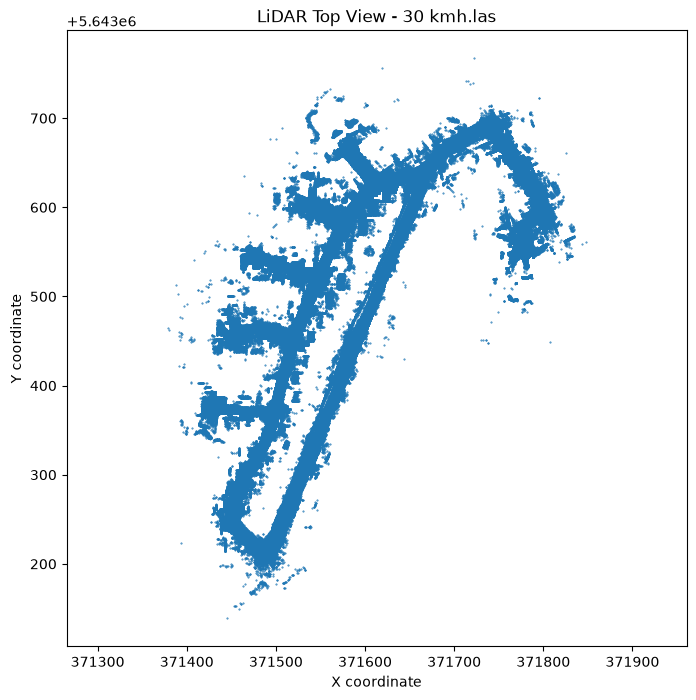


Processing: 20 kmh.las
Sample size: (1345000, 3)


(plot removed)



Processing: 40 kmh.las
Sample size: (1060000, 3)


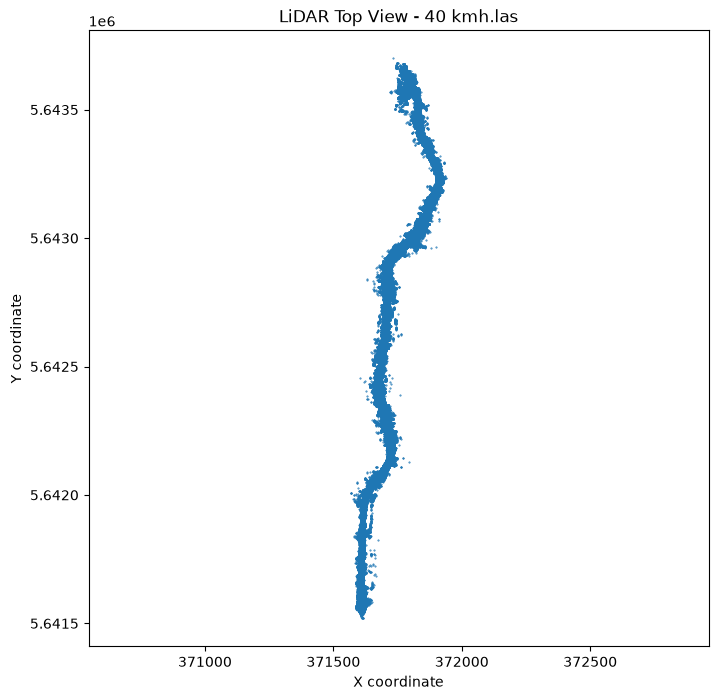

In [ ]:
# lidar data top view visualization of each file using sample points

folder = "../data/pointclouds"

sampled_data = {}

for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

        points = sample_las_points(path)

        sampled_data[file] = points

        print("Sample size:", points.shape)


        x = points[:,0]
        y = points[:,1]
        z = points[:,2]


        plt.figure(figsize=(8,8))

        plt.scatter(
            x,
            y,
            s=0.2
        )

        plt.axis("equal")
        plt.xlabel("X coordinate")
        plt.ylabel("Y coordinate")
        plt.title(f"LiDAR Top View - {file}")

        plt.show()


Processing: 30 kmh.las
Sample size: (1045000, 3)


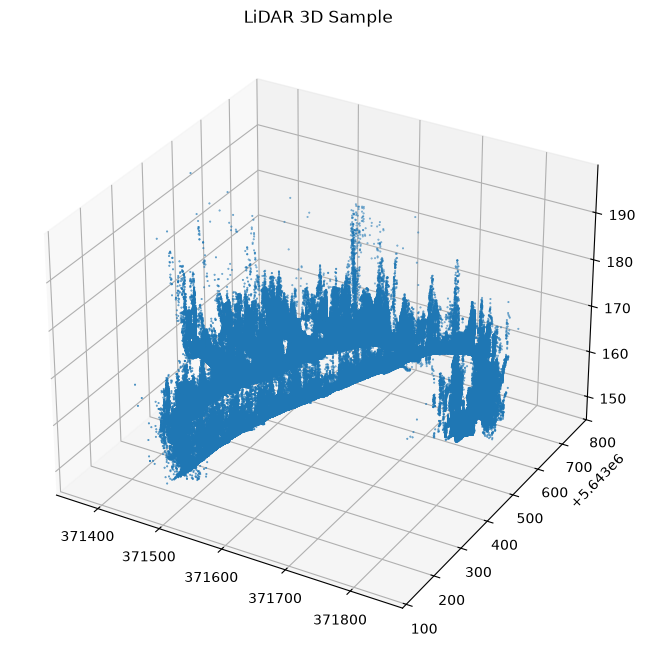


Processing: 20 kmh.las
Sample size: (1345000, 3)


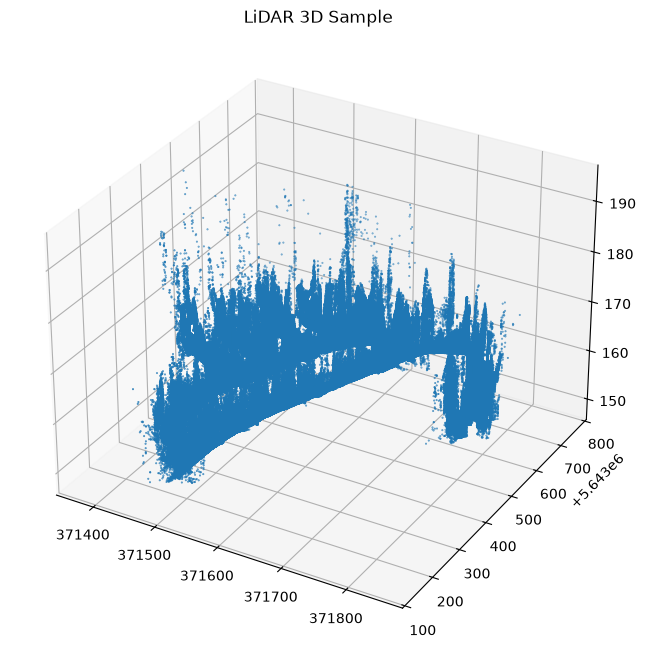


Processing: 40 kmh.las
Sample size: (1060000, 3)


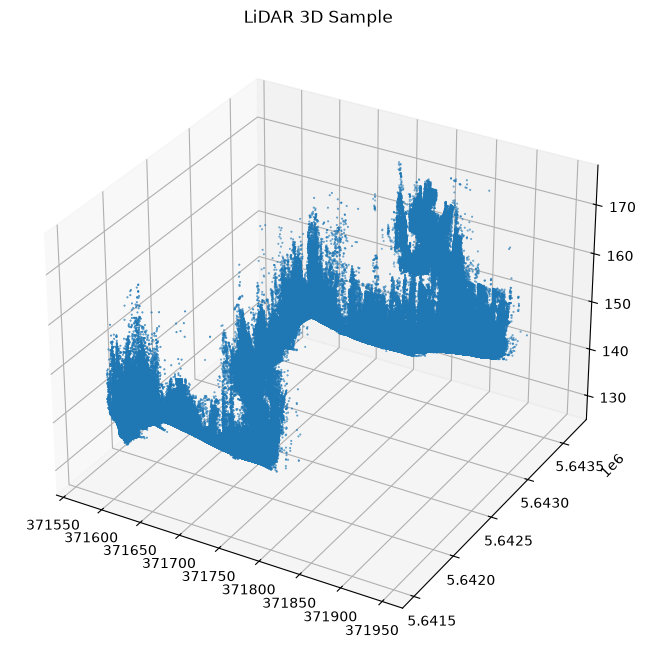

In [ ]:
# lidar data 3d view visualization of each file using sample points

folder = "../data/pointclouds"

sampled_data = {}

for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

        points = sample_las_points(path)

        sampled_data[file] = points

        print("Sample size:", points.shape)

        fig = plt.figure(figsize=(10,8))

        ax = fig.add_subplot(111, projection='3d')


        ax.scatter(
            points[:,0],
            points[:,1],
            points[:,2],
            s=0.2
        )


        ax.set_title("LiDAR 3D Sample")

        plt.show()


Processing: 30 kmh.las
Sample size: (1045000, 3)


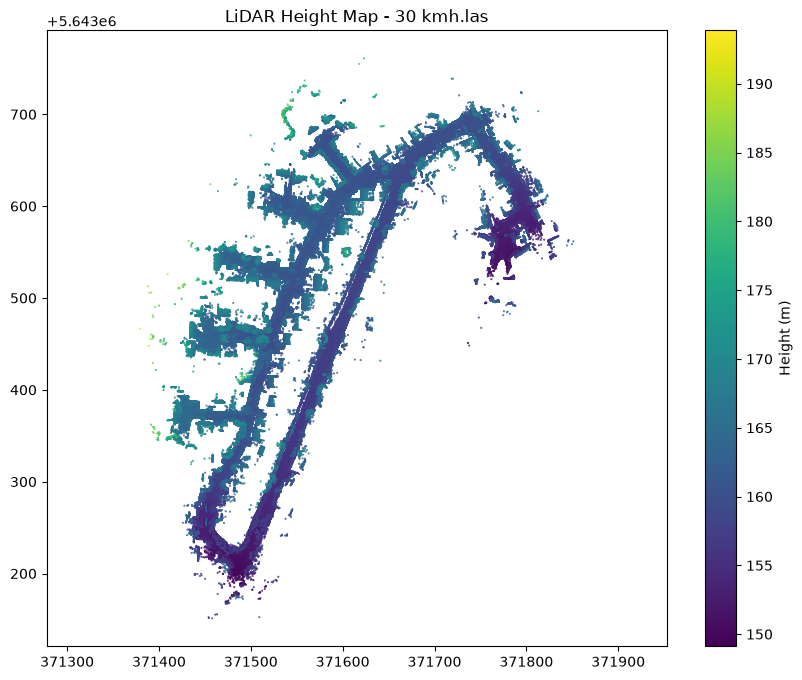


Processing: 20 kmh.las
Sample size: (1345000, 3)


(plot removed)



Processing: 40 kmh.las
Sample size: (1060000, 3)


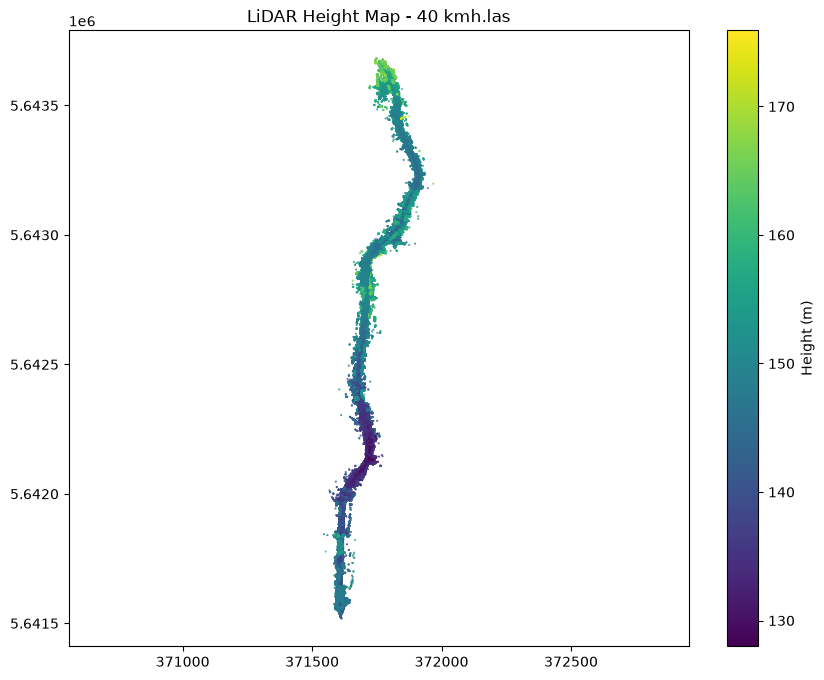

In [ ]:
# lidar data height map visualization of each file using sample points

folder = "../data/pointclouds"
sampled_data = {}

for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

        points = sample_las_points(path)

        sampled_data[file] = points

        print("Sample size:", points.shape)


        x = points[:,0]
        y = points[:,1]
        z = points[:,2]


        plt.figure(figsize=(10,8))

        plt.scatter(
            x,
            y,
            c=z,
            s=0.2
        )

        plt.colorbar(label="Height (m)")

        plt.axis("equal")
        plt.title(f"LiDAR Height Map - {file}")

        plt.show()

In [ ]:
# Analysis of lidar data z (heigth) values

folder = "../data/pointclouds"


for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)
  

        print("Minimum height:", np.min(z))
        print("Maximum height:", np.max(z))

        print("Mean height:", np.mean(z))
        print("Median height:", np.median(z))
        print("Height standard deviation:", np.std(z))
                


Processing: 30 kmh.las
Minimum height: 127.98699999999998
Maximum height: 175.91899999999998
Mean height: 145.08018500849056
Median height: 144.999
Height standard deviation: 8.026880528598959

Processing: 20 kmh.las
Minimum height: 127.98699999999998
Maximum height: 175.91899999999998
Mean height: 145.08018500849056
Median height: 144.999
Height standard deviation: 8.026880528598959

Processing: 40 kmh.las
Minimum height: 127.98699999999998
Maximum height: 175.91899999999998
Mean height: 145.08018500849056
Median height: 144.999
Height standard deviation: 8.026880528598959



Processing: 30 kmh.las
Sample size: (1045000, 3)


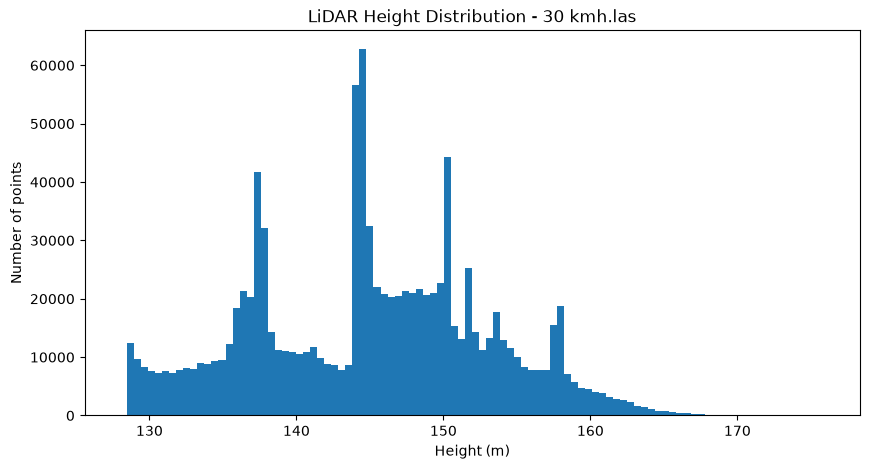


Processing: 20 kmh.las
Sample size: (1345000, 3)


(plot removed)



Processing: 40 kmh.las
Sample size: (1060000, 3)


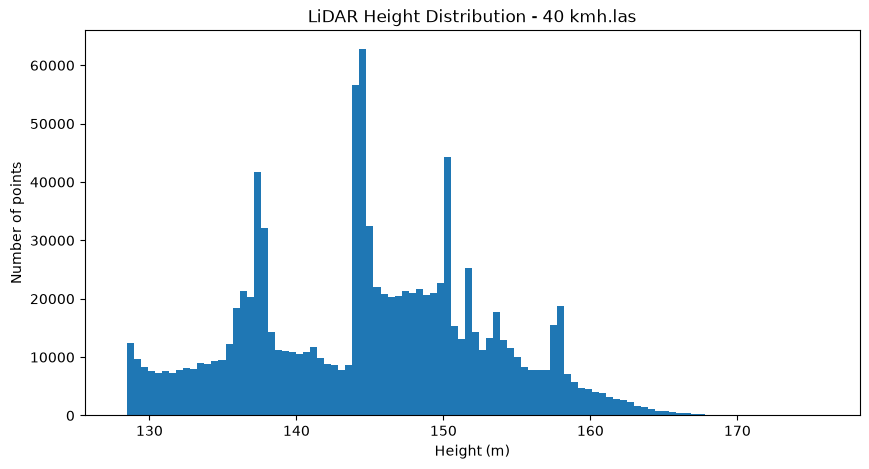

In [ ]:
# lidar data heigth distribution



folder = "../data/pointclouds"

sampled_data = {}

for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

        points = sample_las_points(path)

        sampled_data[file] = points

        print("Sample size:", points.shape)



        plt.figure(figsize=(10,5))

        plt.hist(
            z,
            bins=100
        )

        plt.xlabel("Height (m)")
        plt.ylabel("Number of points")
        plt.title(f"LiDAR Height Distribution - {file}")

        plt.show()

In [ ]:
# lidar data r g b attributes range of each file using sample points

folder = "../data/pointclouds"



for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

       

        with laspy.open(path) as f:

            chunk = next(f.chunk_iterator(100000))

            print("Red range:")
            print(chunk.red.min(), chunk.red.max())

            print("Green range:")
            print(chunk.green.min(), chunk.green.max())

            print("Blue range:")
            print(chunk.blue.min(), chunk.blue.max())


Processing: 30 kmh.las
Sample size: (1045000, 3)
Red range:
0 65535
Green range:
0 65535
Blue range:
0 65535

Processing: 20 kmh.las
Sample size: (1345000, 3)
Red range:
0 65535
Green range:
0 65535
Blue range:
0 65535

Processing: 40 kmh.las
Sample size: (1060000, 3)
Red range:
0 65535
Green range:
0 65021
Blue range:
0 65535


In [ ]:
# Analysis of lidar data intensity values

folder = "../data/pointclouds"



for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

        
        with laspy.open(path) as f:

            chunk = next(f.chunk_iterator(100000))

            intensity = np.array(chunk.intensity)
            
        print("Minimum intensity:", intensity.min())
        print("Maximum intensity:", intensity.max())
        print("Mean intensity:", intensity.mean())
        print("Median intensity:", np.median(intensity))


Processing: 30 kmh.las
Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 61.33409
Median intensity: 44.0

Processing: 20 kmh.las
Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 65.12362
Median intensity: 40.0

Processing: 40 kmh.las
Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 41.05543
Median intensity: 28.0



Processing: 30 kmh.las
Sample size: (1045000, 3)


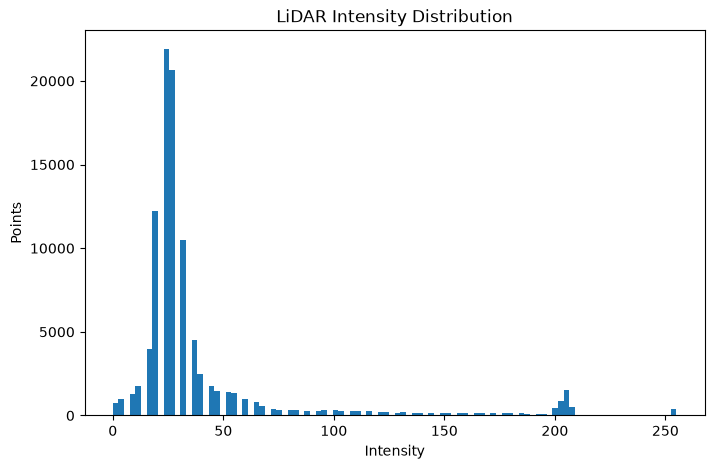


Processing: 20 kmh.las
Sample size: (1345000, 3)


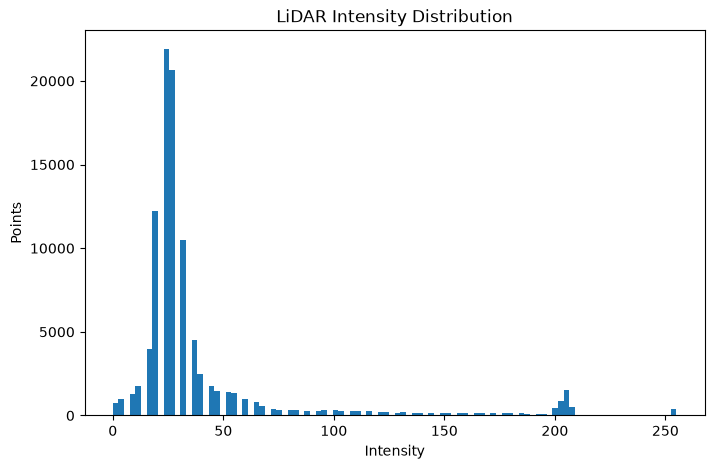


Processing: 40 kmh.las
Sample size: (1060000, 3)


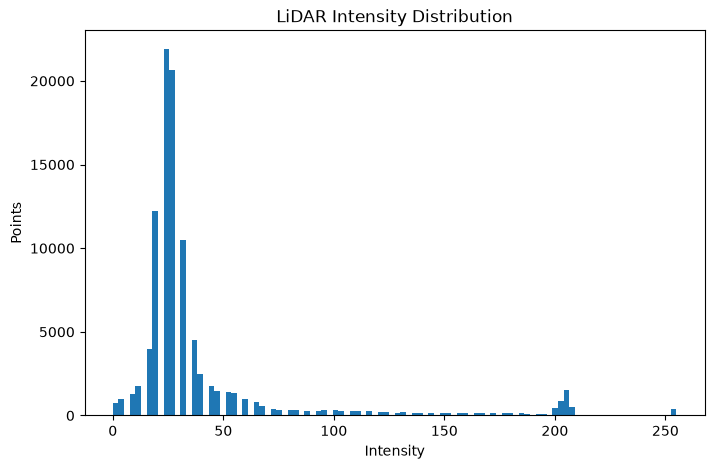

In [ ]:
# lidar data intensity distribution


folder = "../data/pointclouds"

sampled_data = {}

for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

        points = sample_las_points(path)

        sampled_data[file] = points

        print("Sample size:", points.shape)

        plt.figure(figsize=(8,5))

        plt.hist(
            intensity,
            bins=100
        )

        plt.xlabel("Intensity")
        plt.ylabel("Points")
        plt.title("LiDAR Intensity Distribution")

        plt.show()

In [ ]:
# lidar data return number & number of returns of each file using sample points



folder = "../data/pointclouds"


for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

        

        with laspy.open(path) as f:

            chunk = next(f.chunk_iterator(100000))

            return_number = np.array(chunk.return_number)
            total_returns = np.array(chunk.number_of_returns)


        print("Return number distribution:")
        print(np.unique(return_number, return_counts=True))


        print("\nNumber of returns distribution:")
        print(np.unique(total_returns, return_counts=True))


Processing: 30 kmh.las
Return number distribution:
(array([1, 2], dtype=uint8), array([91650,  8350]))

Number of returns distribution:
(array([0], dtype=uint8), array([100000]))

Processing: 20 kmh.las
Return number distribution:
(array([1, 2], dtype=uint8), array([92250,  7750]))

Number of returns distribution:
(array([0], dtype=uint8), array([100000]))

Processing: 40 kmh.las
Return number distribution:
(array([1, 2], dtype=uint8), array([96406,  3594]))

Number of returns distribution:
(array([0], dtype=uint8), array([100000]))


In [ ]:
# lidar data number of returns of each file using sample points



folder = "../data/pointclouds"

sampled_data = {}

for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

        points = sample_las_points(path)

        sampled_data[file] = points

        print("Sample size:", points.shape)
        
        with laspy.open(path) as f:

            counts = {}

            for chunk in f.chunk_iterator(500000):

                values = np.array(chunk.number_of_returns)

                unique, nums = np.unique(
                    values,
                    return_counts=True
                )

                for u,n in zip(unique,nums):
                    counts[u] = counts.get(u,0)+n


        print(counts)


Processing: 20 kmh.las
Sample size: (1345000, 3)
{np.uint8(0): np.int64(134129902)}

Processing: 30 kmh.las
Sample size: (1045000, 3)
{np.uint8(0): np.int64(104427485)}

Processing: 40 kmh.las
Sample size: (1060000, 3)
{np.uint8(0): np.int64(105708638)}


In [ ]:
# lidar data class id of each file using sample points


path = "../data/pointclouds/20 kmh.las"

class_counts = {}

with laspy.open(path) as f:

    for chunk in f.chunk_iterator(500000):

        classes = np.array(chunk.classification)

        unique, counts = np.unique(
            classes,
            return_counts=True
        )

        for c,n in zip(unique,counts):
            class_counts[c] = class_counts.get(c,0)+n


print(class_counts)

In [ ]:
# HAL and VL pipeline data  Available information

hal = gpd.read_file("../data/leitungen/HAL.shp")
vl = gpd.read_file("../data/leitungen/VL.shp")

print("HAL")
print("Segments:", len(hal))
print("CRS:", hal.crs)
print("Geometry:", hal.geom_type.unique())
print("Total length (m):", hal.length.sum())


print("\nVL")
print("Segments:", len(vl))
print("CRS:", vl.crs)
print("Geometry:", vl.geom_type.unique())
print("Total length (m):", vl.length.sum())

HAL
Segments: 31
CRS: EPSG:25832
Geometry: <StringArray>
['LineString']
Length: 1, dtype: str
Total length (m): 702.1429916726289

VL
Segments: 5
CRS: EPSG:25832
Geometry: <StringArray>
['LineString']
Length: 1, dtype: str
Total length (m): 1311.9772673329398


In [ ]:
hal = gpd.read_file("../data/leitungen/HAL.shp")
vl = gpd.read_file("../data/leitungen/VL.shp")


print("HAL")
print(hal.info())

print("\nVL")
print(vl.info())

HAL
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id        0 non-null      float64 
 1   geometry  31 non-null     geometry
dtypes: float64(1), geometry(1)
memory usage: 628.0 bytes
None

VL
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id        0 non-null      float64 
 1   geometry  5 non-null      geometry
dtypes: float64(1), geometry(1)
memory usage: 212.0 bytes
None


In [71]:
print("HAL geometry:")
print(hal.geom_type.value_counts())


print("\nVL geometry:")
print(vl.geom_type.value_counts())

HAL geometry:
LineString    31
Name: count, dtype: int64

VL geometry:
LineString    5
Name: count, dtype: int64


In [72]:
print(
    "HAL total length:",
    hal.length.sum(),
    "meters"
)


print(
    "VL total length:",
    vl.length.sum(),
    "meters"
)

HAL total length: 702.1429916726289 meters
VL total length: 1311.9772673329398 meters


In [ ]:
# Check coordinate system

hal_lidar = hal.to_crs("EPSG:32632")
vl_lidar = vl.to_crs("EPSG:32632")

print(hal_lidar.crs)
print(vl_lidar.crs)

EPSG:32632
EPSG:32632


In [ ]:
# Check pipeline bounds

print("HAL bounds:")
print(hal.total_bounds)


print("\nVL bounds:")
print(vl.total_bounds)

HAL bounds:
[ 371429.14542585 5643223.45726301  371791.49619759 5643706.22389856]

VL bounds:
[ 371433.77614321 5643215.96429275  371797.19498235 5643695.87424952]


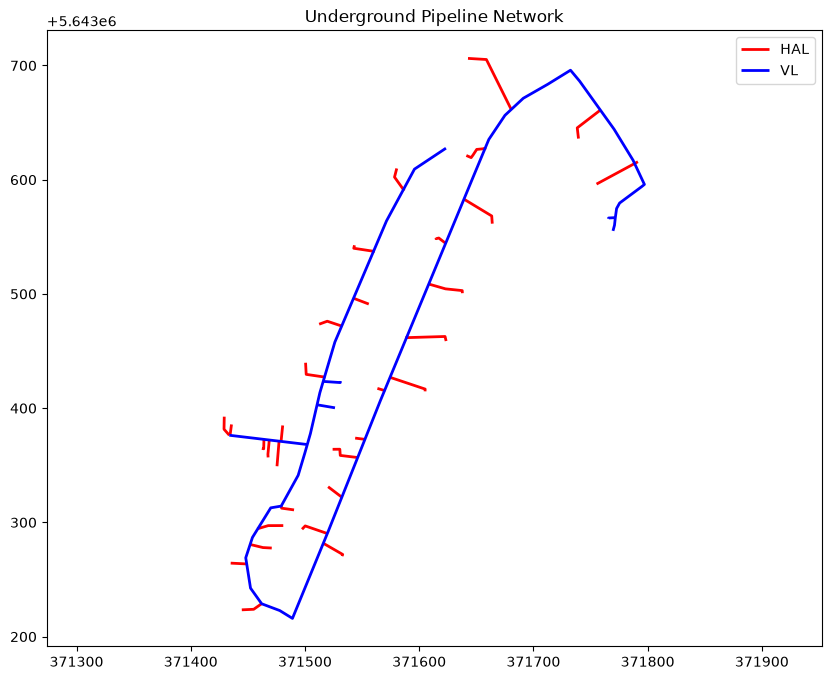

In [ ]:
# plot underground pipeline network


fig, ax = plt.subplots(figsize=(10,8))


hal.plot(
    ax=ax,
    color="red",
    linewidth=2,
    label="HAL"
)


vl.plot(
    ax=ax,
    color="blue",
    linewidth=2,
    label="VL"
)


plt.legend()
plt.axis("equal")
plt.title("Underground Pipeline Network")

plt.show()


Processing: 30 kmh.las
Sample size: (1045000, 3)


<Figure size 800x800 with 0 Axes>

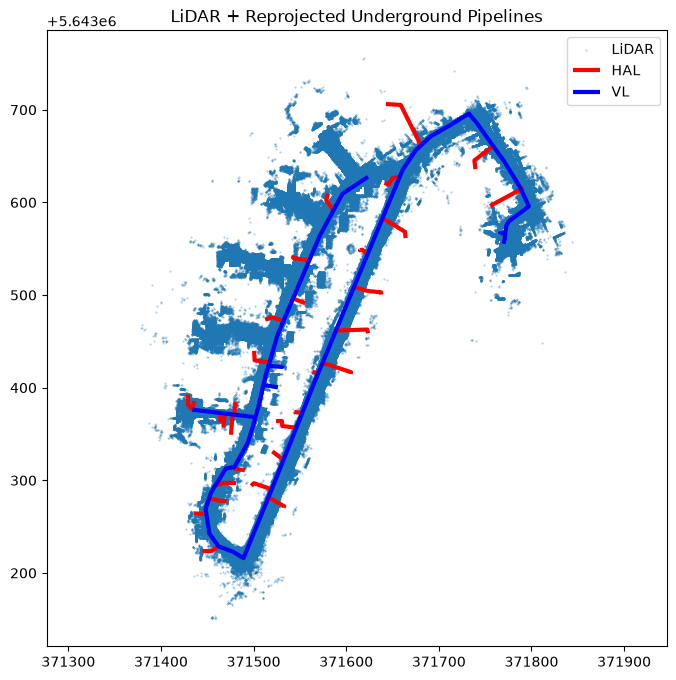


Processing: 20 kmh.las
Sample size: (1345000, 3)


<Figure size 800x800 with 0 Axes>

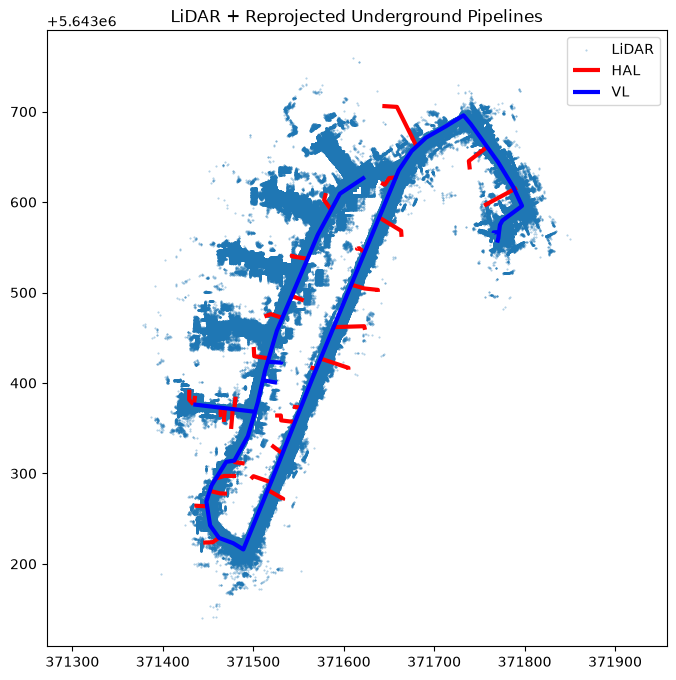


Processing: 40 kmh.las
Sample size: (1060000, 3)


<Figure size 800x800 with 0 Axes>

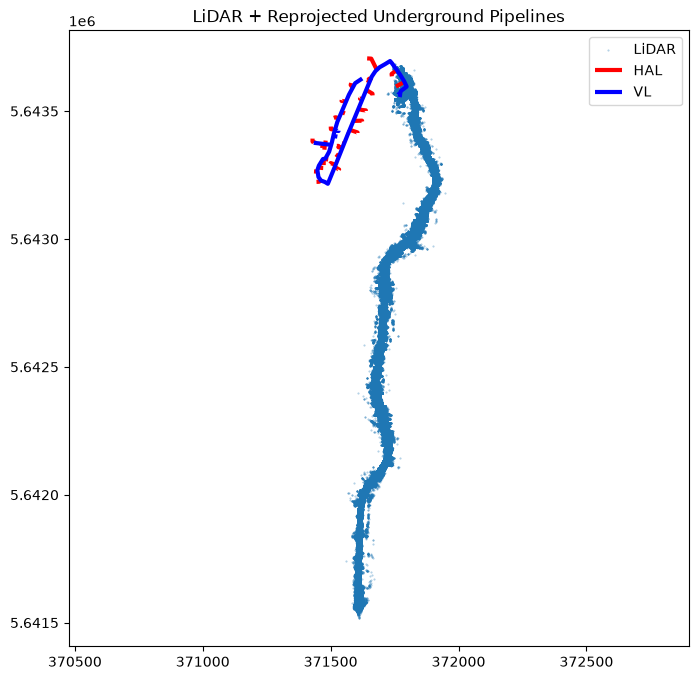

In [ ]:
# plot reprojected underground pipeline network & Lidar

folder = "../data/pointclouds"

sampled_data = {}

for file in os.listdir(folder):

    if file.endswith(".las"):

        path = os.path.join(folder, file)

        print("\nProcessing:", file)

        points = sample_las_points(path)

        sampled_data[file] = points

        print("Sample size:", points.shape)


        x = points[:,0]
        y = points[:,1]
        z = points[:,2]


        plt.figure(figsize=(8,8))

        fig, ax = plt.subplots(figsize=(8,8))

        # LiDAR sampled points
        ax.scatter(
            x,
            y,
            s=0.2,
            alpha=0.4,
            label="LiDAR"
        )

        # Reprojected pipelines
        hal_lidar.plot(
            ax=ax,
            color="red",
            linewidth=3,
            label="HAL"
        )

        vl_lidar.plot(
            ax=ax,
            color="blue",
            linewidth=3,
            label="VL"
        )

        plt.axis("equal")
        plt.legend()
        plt.title("LiDAR + Reprojected Underground Pipelines")

        plt.show()